In [1]:
# Xây dựng BasicBlock
import torch
import torch.nn as nn
import torch.optim as optim

class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # Nhánh chính
        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut
        self.shortcut = nn.Identity()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity
        out = self.relu(out)

        return out

In [2]:
# Xây dựng toàn bộ ResNet-18
class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()

        self.in_channels = 64

        # Stem
        self.conv1 = nn.Conv2d(
            3, 64,
            kernel_size=7, stride=2, padding=3,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.maxpool = nn.MaxPool2d(
            kernel_size=3, stride=2, padding=1
        )

        # 4 nhóm Residual Blocks
        self.layer1 = self._make_layer(64, blocks=2, stride=1)
        self.layer2 = self._make_layer(128, blocks=2, stride=2)
        self.layer3 = self._make_layer(256, blocks=2, stride=2)
        self.layer4 = self._make_layer(512, blocks=2, stride=2)

        # Global Average Pooling + FC
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, out_channels, blocks, stride):
        layers = []

        layers.append(
            BasicBlock(self.in_channels, out_channels, stride)
        )

        self.in_channels = out_channels

        for _ in range(1, blocks):
            layers.append(
                BasicBlock(self.in_channels, out_channels)
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x

In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = ResNet18(num_classes=21).to(device)

print(model)

# Kiểm tra output shape
model.eval()

with torch.no_grad():
    x = torch.randn(2, 3, 224, 224).to(device)
    output = model(x)

print("Output shape:", output.shape)

ResNet18(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=Tru

In [4]:
# Chuẩn bị dữ liệu VinaFood21
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

DATA_DIR = r"C:\Users\Thao\Downloads\VinaFood21\VinaFood21"

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

train_folder = os.path.join(DATA_DIR, "train")
val_folder = os.path.join(DATA_DIR, "val")

full_train_aug = datasets.ImageFolder(
    train_folder,
    transform=train_transform
)

full_train_eval = datasets.ImageFolder(
    train_folder,
    transform=eval_transform
)

test_ds = datasets.ImageFolder(
    val_folder,
    transform=eval_transform
)

assert len(full_train_aug.classes) == 21
assert full_train_aug.class_to_idx == test_ds.class_to_idx

n_train = int(0.9 * len(full_train_aug))

generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    len(full_train_aug),
    generator=generator
).tolist()

train_indices = indices[:n_train]
val_indices = indices[n_train:]

train_ds = Subset(full_train_aug, train_indices)
val_ds = Subset(full_train_eval, val_indices)

train_dl = DataLoader(
    train_ds, batch_size=16, shuffle=True
)

val_dl = DataLoader(
    val_ds, batch_size=16, shuffle=False
)

test_dl = DataLoader(
    test_ds, batch_size=16, shuffle=False
)

classes = full_train_aug.classes

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

Train: 9039
Validation: 1005
Test: 6682


In [5]:
# Khởi tạo Loss và Adam Optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 20

In [6]:
# Hàm Training
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Xóa gradient batch trước
        optimizer.zero_grad()

        # Forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward và cập nhật trọng số
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [7]:
# Hàm Validation
@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [8]:
# Training Loop
train_losses = []
val_losses = []
train_accs = []
val_accs = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )

    val_loss, val_acc = validate(
        model, val_dl, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            model.state_dict(),
            "best_resnet18.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

C:\Users\Thao\AppData\Local\Programs\Python\Python313\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/20] | Train Loss: 2.7763 | Train Acc: 0.1707 | Val Loss: 2.6274 | Val Acc: 0.2139
Epoch [2/20] | Train Loss: 2.4737 | Train Acc: 0.2445 | Val Loss: 2.3182 | Val Acc: 0.2816
Epoch [3/20] | Train Loss: 2.3091 | Train Acc: 0.2821 | Val Loss: 2.2320 | Val Acc: 0.2876
Epoch [8/20] | Train Loss: 1.7482 | Train Acc: 0.4489 | Val Loss: 1.8348 | Val Acc: 0.4169
Epoch [9/20] | Train Loss: 1.6385 | Train Acc: 0.4845 | Val Loss: 1.6094 | Val Acc: 0.4826
Epoch [10/20] | Train Loss: 1.5451 | Train Acc: 0.5107 | Val Loss: 1.6902 | Val Acc: 0.4806
Epoch [11/20] | Train Loss: 1.4550 | Train Acc: 0.5440 | Val Loss: 1.7441 | Val Acc: 0.4905
Epoch [12/20] | Train Loss: 1.3564 | Train Acc: 0.5709 | Val Loss: 1.6014 | Val Acc: 0.4826
Epoch [13/20] | Train Loss: 1.2527 | Train Acc: 0.5997 | Val Loss: 1.5753 | Val Acc: 0.5333
Epoch [14/20] | Train Loss: 1.1618 | Train Acc: 0.6261 | Val Loss: 1.5095 | Val Acc: 0.5353
Epoch [15/20] | Train Loss: 1.0255 | Train Acc: 0.6652 | Val Loss: 1.8340 | Val Acc: 

In [9]:
# Đánh giá Accuracy, Precision, Recall, F1-macro
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

model.load_state_dict(
    torch.load(
        "best_resnet18.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_dl:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(preds.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-macro:  {f1:.4f}")

print(classification_report(
    y_true, y_pred,
    labels=list(range(21)),
    target_names=classes,
    zero_division=0
))

Accuracy:  0.5015
Precision: 0.5286
Recall:    0.5006
F1-macro:  0.4888
                  precision    recall  f1-score   support

        banh-can       0.56      0.29      0.38       241
        banh-hoi       0.59      0.59      0.59       607
    banh-mi-chao       0.59      0.70      0.64       289
        banh-tet       0.82      0.37      0.51       364
 banh-trang-tron       0.56      0.21      0.30       309
          banh-u       0.22      0.74      0.34       176
        banh-uot       0.54      0.23      0.33       560
       bap-nuong       0.57      0.30      0.39       143
          bo-kho       0.50      0.55      0.52       338
       bo-la-lot       0.69      0.72      0.71       458
       bot-chien       0.47      0.51      0.49       276
           ca-ri       0.37      0.19      0.25       171
    canh-kho-qua       0.63      0.68      0.66       290
   canh-khoai-mo       0.88      0.72      0.79       198
        ga-nuong       0.41      0.48      0.44       372

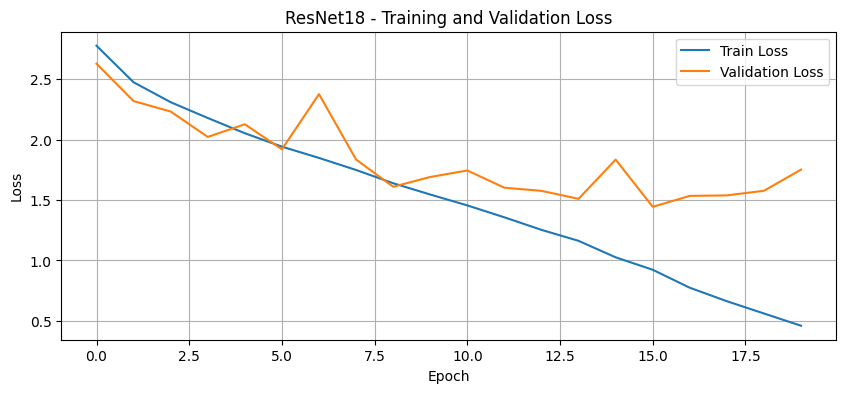

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet18 - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

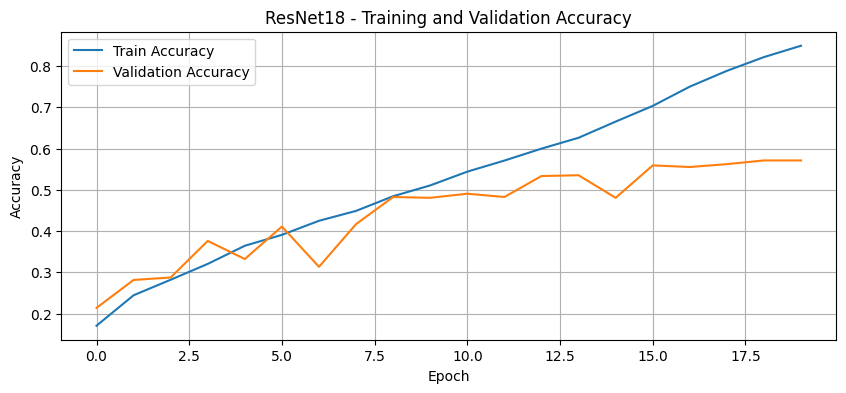

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet18 - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

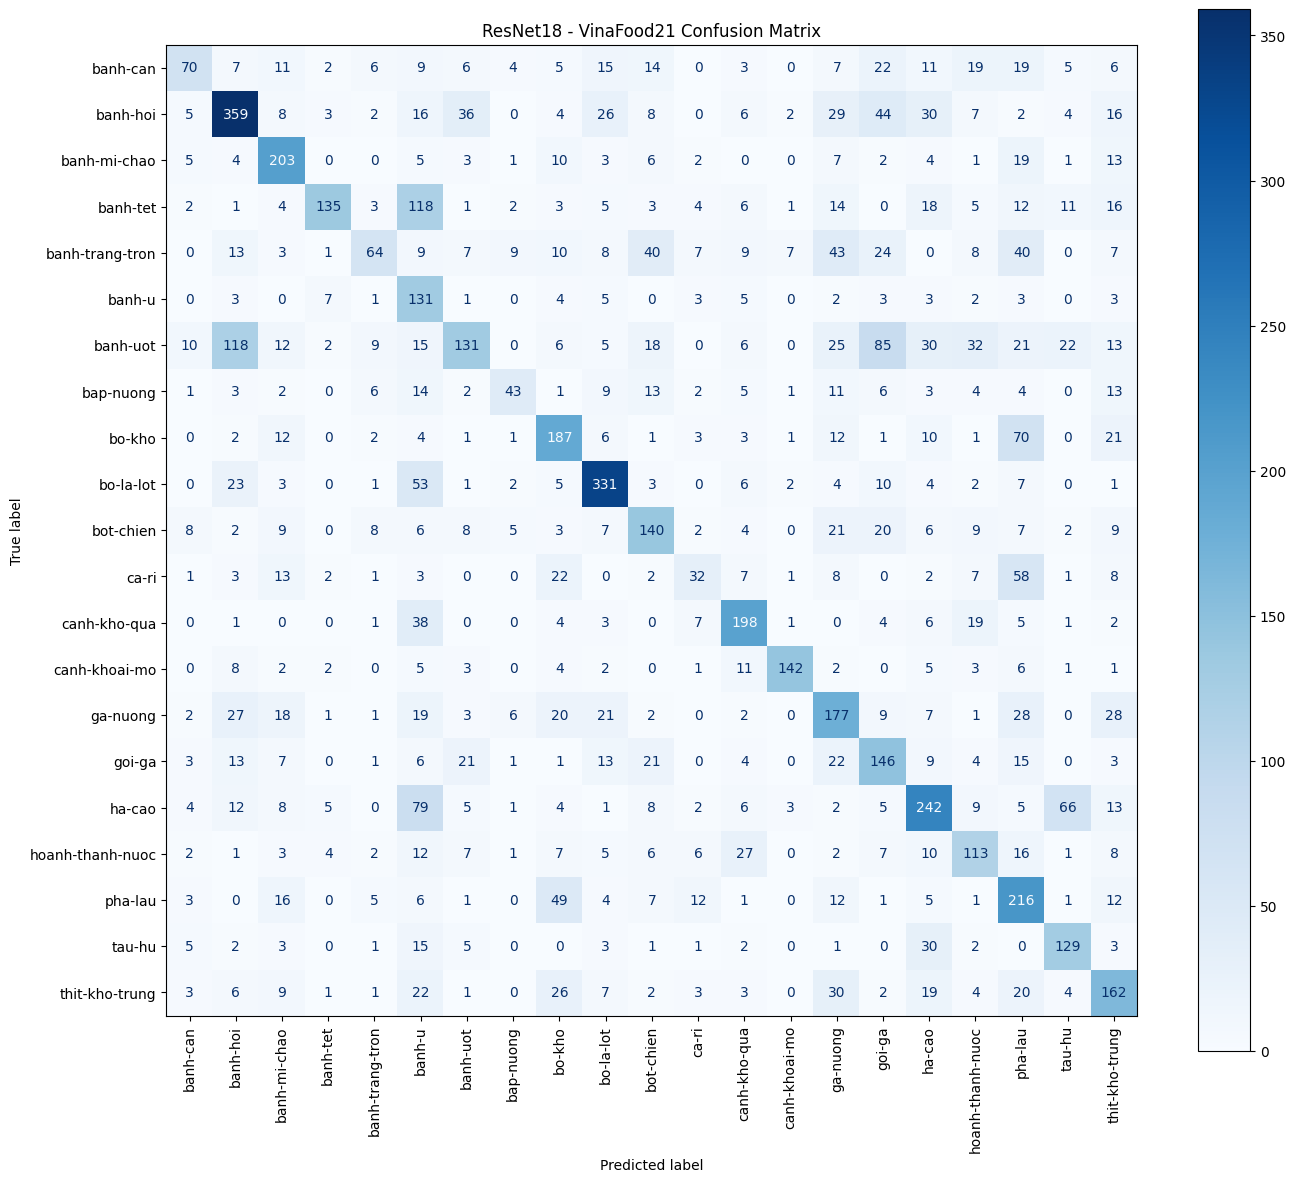

In [12]:
fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(21)),
    display_labels=classes,
    cmap="Blues",
    xticks_rotation=90,
    ax=ax
)

plt.title("ResNet18 - VinaFood21 Confusion Matrix")
plt.tight_layout()
plt.show()